# WNT plate complexity

Complexity (`l_cross`) of every organoid in `Data/wnt_pert` that passed the discards, as stored in `Data/npz/wnt_master.npz` (`compute_master_npz.py --complexity-only`): the control wells against each IWP2 condition. Wells of a condition are pooled.


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from scipy.stats import mannwhitneyu

ORDER  = ['control', 'IWP2_24hr', 'IWP2_60hr', 'IWP2_60hr_HiWnt']
COLOUR = dict(zip(ORDER, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))
INK, MUTED = '#0b0b0b', '#52514e'

m = np.load('Data/npz/wnt_master.npz', allow_pickle=True)
wells = json.load(open('Data/wnt_pert/config.json'))['condition_by_token']['map']
errors = m['complexity_errors'].astype(float)
df = pd.DataFrame({'uid': m['ids'].astype(str), 'condition': m['conditions'].astype(str),
                   'area': m['areas'], 'l_cross': m['l_cross_values']})
df['well'] = df['uid'].str.split('_').str[-2]
assert all(wells[w] == c for w, c in zip(df['well'], df['condition']))
for l in range(errors.shape[1]):
    df[f'error_lmax{l}'] = errors[:, l]
df = df[['uid', 'condition', 'well', 'area', 'l_cross'] + [f'error_lmax{l}' for l in range(errors.shape[1])]]

out_path = 'output/wnt_complexity.csv'
df.to_csv(out_path, index=False)
print(f'wrote {len(df)} organoids -> {out_path}')


wrote 871 organoids -> output/wnt_complexity.csv


`output/wnt_complexity.csv` has one row per organoid. `error_lmax{l}` is the area-normalised RMSE of the reconstruction from degrees 0 to *l*, and `area` is in pipeline units (× 100 = µm²).

Each condition against control: `P(> control)` is the probability that a random organoid of the condition is more complex than a random control organoid, with a two-sided Mann–Whitney U test on the pooled organoids. The per-well medians show whether the duplicate wells agree.


In [2]:
control = df.loc[df.condition == 'control', 'l_cross']
rows = []
for c in ORDER:
    x = df.loc[df.condition == c, 'l_cross']
    row = {'condition': c, 'n': len(x), 'median': x.median(), 'q25': x.quantile(.25), 'q75': x.quantile(.75),
           'well medians': ', '.join(f'{w} {v:.2f}' for w, v in df[df.condition == c].groupby('well')['l_cross'].median().items())}
    if c != 'control':
        u, p = mannwhitneyu(x, control, alternative='two-sided')
        row.update({'Δ median': x.median() - control.median(), 'P(> control)': u / (len(x) * len(control)), 'p': f'{p:.1e}'})
    rows.append(row)
stats = pd.DataFrame(rows).set_index('condition')
stats.round(3)


,n,median,q25,q75,well medians,Δ median,P(> control),p
condition,,,,,,,,
control,242,3.162,2.607,3.872,"D02 3.10, D03 3.20",NaN,NaN,NaN
IWP2_24hr,231,1.808,1.018,2.444,"E02 1.91, E03 1.72",-1.354,0.133,2.3e-43
IWP2_60hr,246,1.164,0.996,1.852,"D07 1.06, D08 1.23",-1.998,0.061,2.8e-63
IWP2_60hr_HiWnt,152,1.583,0.997,2.454,"C07 2.12, C08 1.26",-1.579,0.132,1.0e-34


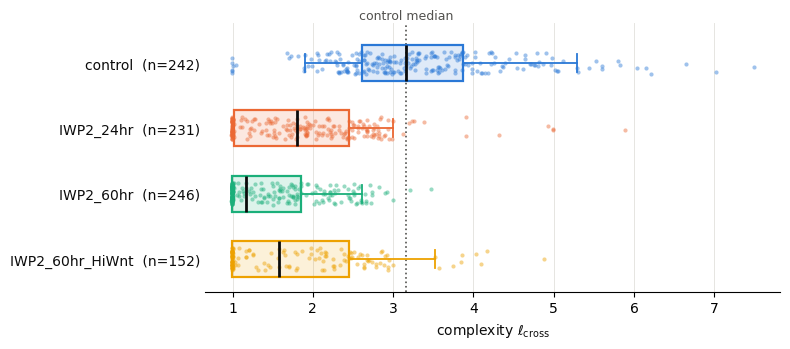

In [3]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, c in enumerate(ORDER):
    x = df.loc[df.condition == c, 'l_cross']
    ax.scatter(x, i + rng.uniform(-0.17, 0.17, len(x)), s=9, color=COLOUR[c], alpha=0.45, linewidths=0, zorder=2)
    ax.boxplot(x, positions=[i], vert=False, widths=0.55, whis=(5, 95), showfliers=False, patch_artist=True, zorder=3,
               boxprops=dict(facecolor=(*to_rgb(COLOUR[c]), 0.15), edgecolor=COLOUR[c], lw=1.6),
               whiskerprops=dict(color=COLOUR[c], lw=1.3), capprops=dict(color=COLOUR[c], lw=1.3),
               medianprops=dict(color=INK, lw=2))
ax.axvline(control.median(), color=MUTED, lw=1.2, ls=':', zorder=1)
ax.text(control.median(), -0.62, 'control median', color=MUTED, fontsize=9, ha='center', va='bottom')
ax.set_yticks(range(len(ORDER)))
ax.set_yticklabels([f'{c}  (n={stats.loc[c, "n"]})' for c in ORDER], color=INK)
ax.set_ylim(len(ORDER) - 0.5, -0.6)
ax.set_xlabel('complexity $\\ell_{\\mathrm{cross}}$', color=INK)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', color='#e6e5e1', lw=0.7, zorder=0)
for s in ('top', 'right', 'left'):
    ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig('Figures/wnt_complexity_by_condition.png', dpi=200, bbox_inches='tight')
plt.show()
